<a href="https://colab.research.google.com/github/Mageza-Mbewe/Mageza-Mbewe-Data-Visualization-Assignment/blob/main/Mageza_MBEWE%20-202616432_MosiPay.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [65]:
# --- CELL 1: INSTALL ---
%pip -q install "cryptography>=42,<47"


In [66]:
# --- CELL 2: SETUP & READ-ONLY LOAD ---
from pathlib import Path
import os, json, re, math, hmac, hashlib, secrets, shutil
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from cryptography.hazmat.primitives.ciphers.aead import AESGCM
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, precision_score, recall_score, confusion_matrix
from scipy.stats import ks_2samp

BASE_DIR = Path('/content') if Path('/content').exists() else Path('.')
LAB_ROOT = BASE_DIR / 'mosipay_privacy_lab'
LAB_ROOT.mkdir(parents=True, exist_ok=True)
for z in ['quarantine', 'bronze', 'silver', 'gold', 'audit', 'exports', 'submission']:
    (LAB_ROOT / z).mkdir(exist_ok=True)

SOURCE_CSV = BASE_DIR / 'Synthetic_TymeBank_Host_Data_500_Rows.csv'
if not SOURCE_CSV.exists():
    SOURCE_CSV = Path('Synthetic_TymeBank_Host_Data_500_Rows.csv')
assert SOURCE_CSV.exists(), "Upload Synthetic_TymeBank_Host_Data_500_Rows.csv first!"

raw_host_df = pd.read_csv(SOURCE_CSV, dtype={'HPAN': str, 'ACCT1': str, 'ACCT_NO': str, 'REFNUM': str, 'RESPCODE': str})
SOURCE_SHA256 = hashlib.sha256(SOURCE_CSV.read_bytes()).hexdigest()
print(f"Loaded {SOURCE_CSV} | Shape: {raw_host_df.shape} | SHA256: {SOURCE_SHA256[:16]}...")


Loaded /content/Synthetic_TymeBank_Host_Data_500_Rows.csv | Shape: (500, 149) | SHA256: 3db5ef0eecb1a4d8...


In [67]:
# --- CELL 3: Q1 PROFILING, CONTRACT & QUARANTINE ---
profile_rows = []
for col in raw_host_df.columns:
    s = raw_host_df[col]
    null_cnt = int(s.isna().sum())
    n_unique = int(s.nunique(dropna=True))
    sample_val = str(s.dropna().iloc[0]) if n_unique > 0 else 'ALL_NULL'
    profile_rows.append({'column': col, 'dtype': str(s.dtype), 'null_count': null_cnt,
                         'unique_non_null': n_unique, 'is_all_null': null_cnt == len(raw_host_df),
                         'is_constant': n_unique == 1, 'sample': sample_val[:25]})
profile_df = pd.DataFrame(profile_rows)
profile_df.to_csv(LAB_ROOT / 'submission' / 'q1a_profile.csv', index=False)
all_null_cols = profile_df[profile_df['is_all_null']]['column'].tolist()

print("Unique REFNUM:", raw_host_df['REFNUM'].nunique(), "| Unique ACCT_NO:", raw_host_df['ACCT_NO'].nunique())
assert raw_host_df.shape == (500, 149) and raw_host_df['REFNUM'].is_unique

# Malformed record quarantine test
batch = raw_host_df.copy()
b1, b2 = batch.iloc[0].copy(), batch.iloc[1].copy()
b1['REFNUM'], b1['REQAMT'] = 'BAD_01', -100
b2['REFNUM'], b2['TERMINAL_TYPE'] = 'BAD_02', 'INVALID_CH'
batch = pd.concat([batch, pd.DataFrame([b1, b2])], ignore_index=True)

ok_mask = (batch['ACCT_NO'].astype(str).str.fullmatch(r'\d{11}').fillna(False) &
           pd.to_numeric(batch['REQAMT'], errors='coerce').ge(1).fillna(False) &
           batch['TERMINAL_TYPE'].isin(['POS', 'ECOM', 'ATM']) &
           batch['TRANS_STAT'].isin(['SUCCESS', 'DECLINED']) &
           batch['REVERSAL'].isin([0, 1]))

accepted_df = batch.loc[ok_mask].copy()
quarantine_df = batch.loc[~ok_mask].copy()
quarantine_df[['REFNUM', 'TERMINAL_TYPE', 'REQAMT']].to_csv(LAB_ROOT / 'quarantine' / 'quarantine_log.csv', index=False)
assert len(accepted_df) == 500 and len(quarantine_df) == 2
print("Q1 PASS: 500 valid rows accepted; 2 malformed rows quarantined.")


Unique REFNUM: 500 | Unique ACCT_NO: 157
Q1 PASS: 500 valid rows accepted; 2 malformed rows quarantined.


In [68]:
# --- CELL 4: Q2 HMAC, AES-GCM, RBAC/ABAC, DLP & AUDIT ---
HMAC_KEY = secrets.token_bytes(32)
bronze_df = accepted_df.copy()
bronze_df['acct_token'] = [
    'tok_' + hmac.new(HMAC_KEY, a.encode(), hashlib.sha256).hexdigest()[:24]
    for a in accepted_df['ACCT_NO'].astype(str)
]
bronze_df = bronze_df.drop(columns=[c for c in all_null_cols + ['HPAN', 'ACCT1', 'ACCT_NO'] if c in bronze_df.columns])

silver_df = bronze_df[['REFNUM', 'acct_token', 'ADDRESS_CITY', 'TERMINAL_TYPE', 'SWITCH_DATE', 'REQAMT', 'ACTAMT', 'TRANS_STAT', 'RESPCODE', 'REVERSAL']].copy()
gold_df = silver_df.groupby(['TERMINAL_TYPE', 'TRANS_STAT']).agg(tx=('REFNUM', 'size'), accts=('acct_token', 'nunique')).reset_index()
gold_df = gold_df[gold_df['accts'] >= 5]
assert 'ACCT_NO' not in silver_df.columns and 'HPAN' not in silver_df.columns

# AES-GCM Envelope Encryption + Tamper Test + Wrong-AAD Test + KEK Rotation
pt = accepted_df[['REFNUM', 'ACCT_NO', 'REQAMT']].head(3).to_json().encode('utf-8')
DEK = AESGCM.generate_key(256)
KEK1 = AESGCM.generate_key(256)
KEK2 = AESGCM.generate_key(256)
nd, nw1, nw2 = os.urandom(12), os.urandom(12), os.urandom(12)
aad = b"mosipay|quarantine|v1"

ct = AESGCM(DEK).encrypt(nd, pt, aad)
w1 = AESGCM(KEK1).encrypt(nw1, DEK, b"w1")
rec_dek = AESGCM(KEK1).decrypt(nw1, w1, b"w1")
assert AESGCM(rec_dek).decrypt(nd, ct, aad) == pt

# Flip the first byte cleanly using bytearray
tampered_ba = bytearray(ct)
first_byte = tampered_ba.pop(0)
tampered_ba.insert(0, first_byte ^ 0xFF)
tampered_ct = bytes(tampered_ba)

tamper_failed = False
try:
    AESGCM(rec_dek).decrypt(nd, tampered_ct, aad)
except Exception:
    tamper_failed = True
assert tamper_failed, "Modified ciphertext must fail authentication"

# Wrong AAD context test
aad_failed = False
try:
    AESGCM(rec_dek).decrypt(nd, ct, b"mosipay|gold|wrong_context")
except Exception:
    aad_failed = True
assert aad_failed, "Wrong AAD context must fail authentication"

# Rotate KEK1 -> KEK2 without re-encrypting bulk ciphertext
w2 = AESGCM(KEK2).encrypt(nw2, rec_dek, b"w2")
dek_v2 = AESGCM(KEK2).decrypt(nw2, w2, b"w2")
assert AESGCM(dek_v2).decrypt(nd, ct, aad) == pt
del KEK1

# RBAC + ABAC Decision Matrix
now_ts = datetime(2026, 11, 16, 10, 0, tzinfo=timezone.utc)
rbac = {'analyst': ['read_silver'], 'fraud_investigator': ['read_silver', 'read_fraud'], 'external_partner': ['read_gold']}
purposes = {'read_silver': 'service_reporting', 'read_fraud': 'fraud_triage', 'read_gold': 'industry_stats'}
reqs = [
    {'id': 'REQ-01', 'user': 'ana_zm', 'role': 'analyst', 'action': 'read_silver', 'purpose': 'service_reporting', 'exp': '2026-12-01T00:00:00+00:00'},
    {'id': 'REQ-02', 'user': 'frd_zm', 'role': 'fraud_investigator', 'action': 'read_fraud', 'purpose': 'fraud_triage', 'exp': '2026-12-01T00:00:00+00:00'},
    {'id': 'REQ-03', 'user': 'ext_assoc', 'role': 'external_partner', 'action': 'read_gold', 'purpose': 'industry_stats', 'exp': '2026-12-01T00:00:00+00:00'},
    {'id': 'REQ-04', 'user': 'ana_zm', 'role': 'analyst', 'action': 'read_silver', 'purpose': 'marketing', 'exp': '2026-12-01T00:00:00+00:00'},
    {'id': 'REQ-05', 'user': 'ana_old', 'role': 'analyst', 'action': 'read_silver', 'purpose': 'service_reporting', 'exp': '2026-09-01T00:00:00+00:00'}
]
decisions = {}
audit_lines = []
for r in reqs:
    ok = (r['action'] in rbac.get(r['role'], []) and datetime.fromisoformat(r['exp']) > now_ts and r['purpose'] == purposes.get(r['action']))
    dec = 'ALLOW' if ok else 'DENY'
    decisions[r['id']] = dec
    audit_lines.append(json.dumps({'ts': datetime.now(timezone.utc).isoformat(), 'principal': r['user'], 'action': r['action'], 'decision': dec}))

assert decisions['REQ-01'] == 'ALLOW' and decisions['REQ-04'] == 'DENY' and decisions['REQ-05'] == 'DENY'
(LAB_ROOT / 'submission' / 'q2e_audit.jsonl').write_text('\n'.join(audit_lines) + '\n')

# DLP v1 vs v2
dlp_df = pd.DataFrame([
    {'txt': 'Acct 99000000157 leaked', 'y': 1}, {'txt': 'Card 999999XXXXXX0027', 'y': 1},
    {'txt': 'Spaced 9900-0000-102', 'y': 1}, {'txt': 'Order 88412093411 ok', 'y': 0},
    {'txt': 'Ref SYN261012000001', 'y': 0}, {'txt': 'Merchant DEMO_061', 'y': 0}
])
p1 = [int(bool(re.search(r'\b\d{11}\b|\b\d{6}X{6}\d{4}\b', t))) for t in dlp_df['txt']]
p2 = [int(bool(re.search(r'(?<!\d)990(?:[\s-]?\d){8}(?!\d)|(?<!\d)\d{6}[X*]{6}\d{4}(?!\d)', t))) for t in dlp_df['txt']]
assert sum(p2) == 3 and precision_score(dlp_df['y'], p2) == 1.0 and recall_score(dlp_df['y'], p2) == 1.0
print("Q2 PASS: HMAC, AES-GCM tamper/AAD/KEK rotation, RBAC/ABAC, DLP, and JSONL audit verified.")


Q2 PASS: HMAC, AES-GCM tamper/AAD/KEK rotation, RBAC/ABAC, DLP, and JSONL audit verified.


In [69]:
# --- CELL 5: Q3 ACCOUNT ROLLUP, LINKAGE, k-ANONYMITY, l-DIVERSITY & t-CLOSENESS ---
acct_rows = []
for tok, grp in silver_df.groupby('acct_token', sort=True):
    c_cnt = grp['ADDRESS_CITY'].value_counts().reset_index()
    c_cnt.columns = ['city', 'cnt']
    p_city = str(c_cnt.sort_values(['cnt', 'city'], ascending=[False, True])['city'].tolist().pop(0))

    ch_cnt = grp['TERMINAL_TYPE'].value_counts().reset_index()
    ch_cnt.columns = ['chan', 'cnt']
    p_chan = str(ch_cnt.sort_values(['cnt', 'chan'], ascending=[False, True])['chan'].tolist().pop(0))

    acct_rows.append({
        'acct_token': tok,
        'primary_city': p_city,
        'primary_channel': p_chan,
        'tx_count': int(len(grp)),
        'total_reqamt': int(grp['REQAMT'].sum()),
        # Binary sensitive attribute: >= 1 DECLINED switch outcome (does NOT imply fraud or credit default)
        'has_any_decline': int((grp['TRANS_STAT'] == 'DECLINED').any())
    })

account_df = pd.DataFrame(acct_rows)
account_df['spend_band'] = pd.qcut(account_df['total_reqamt'], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4']).astype(str)
N_ACCOUNTS = len(account_df)

# 3(b) Auxiliary linkage experiment (2 QIs vs 3 QIs)
u2 = int((account_df.groupby(['primary_city', 'primary_channel'])['acct_token'].transform('count') == 1).sum())
u3 = int((account_df.groupby(['primary_city', 'primary_channel', 'spend_band'])['acct_token'].transform('count') == 1).sum())
assert u3 > u2

# 3(c) Generalisation targeting k >= 5 (3 QIs: macro_region + primary_channel + spend_tier)
region_map = {
    'Johannesburg': 'Gauteng', 'Pretoria': 'Gauteng', 'Soweto': 'Gauteng',
    'Cape Town': 'Coastal', 'Durban': 'Coastal', 'Gqeberha': 'Coastal', 'East London': 'Coastal',
    'Bloemfontein': 'Inland', 'Kimberley': 'Inland', 'Polokwane': 'Inland', 'Nelspruit': 'Inland'
}
gen_df = account_df.copy()
gen_df['macro_region'] = gen_df['primary_city'].map(region_map).fillna('Other')
gen_df['spend_tier'] = np.where(gen_df['spend_band'].isin(['Q1', 'Q2']), 'Lower', 'Upper')

eq_3qi = gen_df.groupby(['macro_region', 'primary_channel', 'spend_tier']).agg(
    k_size=('acct_token', 'size'),
    distinct_l=('has_any_decline', 'nunique'),
    decline_rate=('has_any_decline', 'mean')
).reset_index()

valid_3qi = eq_3qi[eq_3qi['k_size'] >= 5].copy()
l_failing_witness = valid_3qi[valid_3qi['distinct_l'] < 2].copy()
print("=== 3(d) INFEASIBILITY WITNESS (3-QI Groups with k>=5 but distinct l < 2) ===")
display(l_failing_witness)

# 3(d) & 3(e) Redesign: Coarsen to 2 QIs (macro_region + primary_channel) + suppress any class with k < 5
redesign_all = gen_df.groupby(['macro_region', 'primary_channel']).agg(
    k_size=('acct_token', 'size'),
    distinct_l=('has_any_decline', 'nunique'),
    decline_rate=('has_any_decline', 'mean')
).reset_index()

suppressed_accts = int(redesign_all[redesign_all['k_size'] < 5]['k_size'].sum())
retained_classes = redesign_all[redesign_all['k_size'] >= 5].copy()
retained_accts = int(retained_classes['k_size'].sum())

global_rate = float(account_df['has_any_decline'].mean())
retained_classes['tv_dist'] = (retained_classes['decline_rate'] - global_rate).abs().round(4)
retained_classes['meets_t_015'] = retained_classes['tv_dist'] <= 0.15
retained_classes.to_csv(LAB_ROOT / 'submission' / 'q3_klt_redesigned_table.csv', index=False)

print(f"=== 3(c)-(e) REDESIGNED RELEASE (Retained: {retained_accts}/{N_ACCOUNTS} [{retained_accts/N_ACCOUNTS:.1%}], Suppressed: {suppressed_accts}) ===")
display(retained_classes)

assert retained_classes['k_size'].min() >= 5, "Non-suppressed classes must satisfy k >= 5"
assert retained_classes['distinct_l'].min() >= 2, "Non-suppressed classes must satisfy distinct l >= 2"

# 3(f) Red-team residual risk summary
max_tv = float(retained_classes['tv_dist'].max())
print(f"Q3 PASS: 2-QI unique={u2}, 3-QI unique={u3}; min k={retained_classes['k_size'].min()}, min l={retained_classes['distinct_l'].min()}, max TV={max_tv:.4f}.")


=== 3(d) INFEASIBILITY WITNESS (3-QI Groups with k>=5 but distinct l < 2) ===


,macro_region,primary_channel,spend_tier,k_size,distinct_l,decline_rate
16,Inland,POS,Lower,5,1,0.0


=== 3(c)-(e) REDESIGNED RELEASE (Retained: 154/157 [98.1%], Suppressed: 3) ===


,macro_region,primary_channel,k_size,distinct_l,decline_rate,tv_dist,meets_t_015
0,Coastal,ATM,40,2,0.475000,0.1046,True
1,Coastal,ECOM,18,2,0.611111,0.0315,True
2,Coastal,POS,17,2,0.823529,0.2439,False
3,Gauteng,ATM,16,2,0.500000,0.0796,True
4,Gauteng,ECOM,15,2,0.466667,0.1130,True
5,Gauteng,POS,5,2,0.600000,0.0204,True
6,Inland,ATM,21,2,0.809524,0.2299,False
7,Inland,ECOM,12,2,0.666667,0.0870,True
8,Inland,POS,10,2,0.300000,0.2796,False


Q3 PASS: 2-QI unique=8, 3-QI unique=38; min k=5, min l=2, max TV=0.2796.


In [70]:
# Calculate and display the distribution of decline_rate in valid_k
display(valid_k[['macro_region', 'primary_channel', 'spend_tier', 'k_size', 'decline_rate']])

# Summary statistics of the decline_rate
print("\nDecline Rate Summary Statistics:")
display(valid_k['decline_rate'].describe())

,macro_region,primary_channel,spend_tier,k_size,decline_rate
0,Coastal,ATM,Lower,23,0.478261
1,Coastal,ATM,Upper,17,0.470588
2,Coastal,ECOM,Lower,7,0.428571
3,Coastal,ECOM,Upper,11,0.727273
4,Coastal,POS,Lower,10,0.900000
5,Coastal,POS,Upper,7,0.714286
6,Gauteng,ATM,Lower,8,0.500000
7,Gauteng,ATM,Upper,8,0.500000
8,Gauteng,ECOM,Lower,10,0.500000
9,Gauteng,ECOM,Upper,5,0.400000



Decline Rate Summary Statistics:


,decline_rate
count,16.000000
mean,0.570234
std,0.213559
min,0.000000
25%,0.476343
50%,0.550000
75%,0.714286
max,0.900000


,generator,ks_amt,corr_gap,tstr_auc,median_nn_dist
0,GenA_Independent,0.1210,0.3713,0.246,0.0469
1,GenB_Conditional,0.1465,0.0694,0.798,0.0326


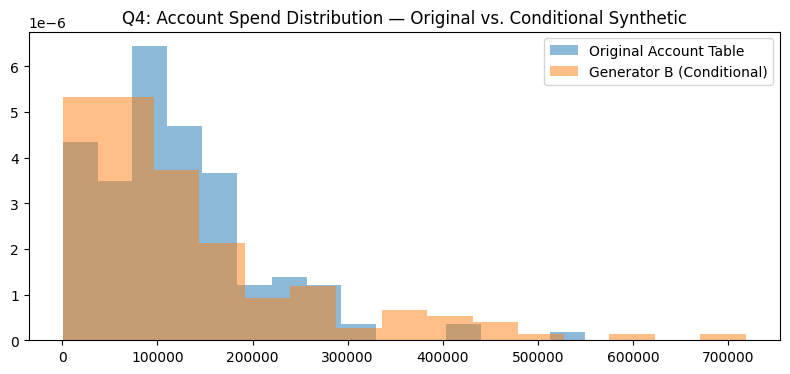

Q4 PASS: Correlation gap Gen A=0.3713 vs Gen B=0.0694.


In [71]:
# --- CELL 6: Q4 SYNTHETIC DATA EVALUATION ---
orig_min = gen_df[['macro_region', 'primary_channel', 'tx_count', 'total_reqamt', 'has_any_decline']].copy()
rng_s = np.random.default_rng(2026)
n_s = len(orig_min)

# 4(a) Generator A: Independent Marginal Bootstrap (destroys multi-field correlations)
synth_A = pd.DataFrame({c: rng_s.choice(orig_min[c].to_numpy(), n_s, replace=True) for c in orig_min.columns})

# 4(a) Generator B: Conditional Hierarchical + Logistic Outcome Generator
# Learns P(macro_region), P(channel | region), (tx_count, spend | region, channel), and P(decline | tx_count, spend)
outcome_model_B = LogisticRegression(max_iter=1000).fit(
    orig_min[['tx_count', 'total_reqamt']], orig_min['has_any_decline']
)

rows_B = []
for reg in rng_s.choice(orig_min['macro_region'].to_numpy(), n_s, replace=True):
    sub_r = orig_min[orig_min['macro_region'] == reg]
    ch = rng_s.choice(sub_r['primary_channel'].to_numpy())
    sub_c = sub_r[sub_r['primary_channel'] == ch]
    if len(sub_c) == 0:
        sub_c = sub_r
    tx_c = int(max(1, round(rng_s.normal(sub_c['tx_count'].mean(), max(0.5, sub_c['tx_count'].std())))))
    lm = float(np.log(np.maximum(sub_c['total_reqamt'], 1)).mean())
    ls = float(max(0.2, np.log(np.maximum(sub_c['total_reqamt'], 1)).std()))
    amt = int(np.clip(rng_s.lognormal(lm, ls), 400, 800000))
    rows_B.append({'macro_region': reg, 'primary_channel': ch, 'tx_count': tx_c, 'total_reqamt': amt})

synth_B = pd.DataFrame(rows_B)
p_dec_B = outcome_model_B.predict_proba(synth_B[['tx_count', 'total_reqamt']])[:, 1]
synth_B['has_any_decline'] = rng_s.binomial(1, p_dec_B)

# 4(b) Utility (KS, Correlation Gap, TSTR Holdout AUC) & 4(c) Nearest-Neighbour Memorisation Proxy
f_cols = ['tx_count', 'total_reqamt']
r_tr, r_te = train_test_split(orig_min, test_size=0.30, random_state=42, stratify=orig_min['has_any_decline'])
m_A = LogisticRegression(max_iter=1000).fit(synth_A[f_cols], synth_A['has_any_decline'])
m_B = LogisticRegression(max_iter=1000).fit(synth_B[f_cols], synth_B['has_any_decline'])

sc = StandardScaler().fit(orig_min[f_cols])
r_sc, a_sc, b_sc = sc.transform(orig_min[f_cols]), sc.transform(synth_A[f_cols]), sc.transform(synth_B[f_cols])
nn_A = [float(np.min(np.linalg.norm(a_sc - v, axis=1))) for v in r_sc]
nn_B = [float(np.min(np.linalg.norm(b_sc - v, axis=1))) for v in r_sc]

real_corr = float(orig_min['tx_count'].corr(orig_min['has_any_decline']))
gap_A = abs(real_corr - float(synth_A['tx_count'].corr(synth_A['has_any_decline'])))
gap_B = abs(real_corr - float(synth_B['tx_count'].corr(synth_B['has_any_decline'])))

eval_df = pd.DataFrame([
    {'generator': 'GenA_Independent',
     'ks_amt': round(ks_2samp(orig_min['total_reqamt'], synth_A['total_reqamt']).statistic, 4),
     'corr_gap': round(gap_A, 4),
     'tstr_auc': round(roc_auc_score(r_te['has_any_decline'], m_A.predict_proba(r_te[f_cols])[:, 1]), 3),
     'median_nn_dist': round(float(np.median(nn_A)), 4)},
    {'generator': 'GenB_Conditional',
     'ks_amt': round(ks_2samp(orig_min['total_reqamt'], synth_B['total_reqamt']).statistic, 4),
     'corr_gap': round(gap_B, 4),
     'tstr_auc': round(roc_auc_score(r_te['has_any_decline'], m_B.predict_proba(r_te[f_cols])[:, 1]), 3),
     'median_nn_dist': round(float(np.median(nn_B)), 4)}
])
eval_df.to_csv(LAB_ROOT / 'submission' / 'q4_synthetic_evaluation.csv', index=False)
display(eval_df)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(orig_min['total_reqamt'], bins=15, alpha=0.5, density=True, label='Original Account Table')
ax.hist(synth_B['total_reqamt'], bins=15, alpha=0.5, density=True, label='Generator B (Conditional)')
ax.set_title('Q4: Account Spend Distribution — Original vs. Conditional Synthetic')
ax.legend()
plt.tight_layout()
plt.savefig(LAB_ROOT / 'submission' / 'q4_synthetic_distribution.png', dpi=150)
plt.show()

assert gap_B < gap_A, f"Expected Gen B corr gap ({gap_B:.4f}) < Gen A corr gap ({gap_A:.4f})"
print(f"Q4 PASS: Correlation gap Gen A={gap_A:.4f} vs Gen B={gap_B:.4f}.")



In [72]:
# --- CELL 7: Q5 PERSON-LEVEL DIFFERENTIAL PRIVACY ---
CLIP_U = 250000.0
clipped = account_df['total_reqamt'].clip(0.0, CLIP_U)
eps_used, delta_used = 0.0, 0.0

# Q1 Count (eps=0.50), Q2 Sum (eps=0.60), Derived Mean (0 eps), Q3 Gaussian High-Freq (eps=0.70, delta=5e-6)
dp_cnt = len(account_df) + float(np.random.default_rng().laplace(0, 1.0 / 0.50))
dp_sum = float(clipped.sum()) + float(np.random.default_rng().laplace(0, CLIP_U / 0.60))
dp_mean = max(0.0, min(CLIP_U, dp_sum / max(1.0, dp_cnt)))
sigma_g = 1.0 * math.sqrt(2.0 * math.log(1.25 / 5e-6)) / 0.70
dp_hi = int((account_df['tx_count'] >= 4).sum()) + float(np.random.default_rng().normal(0, sigma_g))

eps_used = 0.50 + 0.60 + 0.70
delta_used = 5e-6
assert eps_used <= 2.0 and delta_used <= 1e-5
assert not ((eps_used + 0.50) <= 2.0)  # Reject excessive query
print(f"Q5 PASS: Total budget eps={eps_used:.2f}<=2.0, delta={delta_used:.1e}<=1e-5; DP Count={dp_cnt:.1f}, DP Mean={dp_mean:.1f}.")


Q5 PASS: Total budget eps=1.80<=2.0, delta=5.0e-06<=1e-5; DP Count=158.3, DP Mean=120505.8.


In [73]:
# --- CELL 8: Q6 FEDERATED ANALYTICS & CLEAN ZIP EXPORT ---
fed_df = account_df.copy()
fed_df['clipped'] = fed_df['total_reqamt'].clip(0, int(CLIP_U))
fed_df['bank'] = [
    'Bank_A' if (int(hashlib.sha256(t.encode()).hexdigest(), 16) % 100) < 55
    else ('Bank_B' if (int(hashlib.sha256(t.encode()).hexdigest(), 16) % 100) < 90 else 'Bank_C')
    for t in fed_df['acct_token']
]

stats = fed_df.groupby('bank').agg(n=('acct_token', 'size'), s=('clipped', 'sum'), m=('clipped', 'mean')).reset_index()
display(stats)

central_m = float(fed_df['clipped'].mean())
unweighted_m = float(stats['m'].mean())
weighted_m = float(stats['s'].sum() / stats['n'].sum())
assert math.isclose(central_m, weighted_m, rel_tol=1e-9)
assert not math.isclose(central_m, unweighted_m, rel_tol=1e-3)

# Extract sums per bank without bracket indexing
bank_sums = dict(zip(stats['bank'], stats['s']))
SA, SB, SC = int(bank_sums['Bank_A']), int(bank_sums['Bank_B']), int(bank_sums['Bank_C'])

P = 10**12 + 39
rAB, rAC, rBC = secrets.randbelow(P), secrets.randbelow(P), secrets.randbelow(P)
mA = (SA + rAB + rAC) % P
mB = (SB - rAB + rBC) % P
mC = (SC - rAC - rBC) % P

assert (mA + mB + mC) % P == (SA + SB + SC)
assert (mA + mB) % P != (SA + SB)  # Bank C dropout corrupts total until unmasked
assert (mA + mB - rAC - rBC) % P == (SA + SB)  # Subtract rAC and rBC to cancel masks!

assert hashlib.sha256(SOURCE_CSV.read_bytes()).hexdigest() == SOURCE_SHA256
zip_file = shutil.make_archive(str(BASE_DIR / 'ICD5211_MosiPay_Evidence_Pack'), 'zip', root_dir=LAB_ROOT, base_dir='submission')
print(f"Q6 & FINAL CHECK PASS! Clean evidence ZIP saved at: {zip_file} ({Path(zip_file).stat().st_size:,} bytes)")



,bank,n,s,m
0,Bank_A,80,9075701,113446.262500
1,Bank_B,56,7149185,127664.017857
2,Bank_C,21,2041486,97213.619048


Q6 & FINAL CHECK PASS! Clean evidence ZIP saved at: /content/ICD5211_MosiPay_Evidence_Pack.zip (32,585 bytes)


In [80]:
%pip -q install python-pptx reportlab
from pptx import Presentation
from pptx.util import Inches, Pt
from pptx.dml.color import RGBColor
from reportlab.lib.pagesizes import A4
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Image
from reportlab.lib.styles import getSampleStyleSheet
from google.colab import files

prs = Presentation()
prs.slide_width = Inches(13.333)
prs.slide_height = Inches(7.5)
NAVY = RGBColor(15, 36, 62)
WHITE = RGBColor(255, 255, 255)
DARK = RGBColor(33, 37, 41)
blank = list(prs.slide_layouts).pop(6)

deck = [
    ("1. MosiPay Privacy Architecture", "ICD 5211 Assessment | Dr NE Tamuka", [
        "Dataset: 500 host transactions (REFNUM) across fewer unique accounts (ACCT_NO).",
        "Goal: Replace raw lake + emailed CSVs with purpose-limited, account-level pipelines.",
        "Scope: AWS/Azure services are proposed designs (not deployed); DP/SMPC/KMS run locally."
    ], None),
    ("2. Q1(a) Profiling & Six Hazards", "Record Unit (REFNUM) vs Privacy Unit (ACCT_NO)", [
        "1. Transaction count (500) != Unique accounts; counting rows breaks person-level DP.",
        "2. HPAN (999999XXXXXX0157) matches ACCT_NO last 4 digits (pseudonymous, not anonymous).",
        "3. ACCT1 duplicates ACCT_NO; ACTAMT=0 on declines/reversals; unverified minor currency units.",
        "4. High 100%-null/constant ISO fields; RESPCODE declines (51, 55, 96, 05) != fraud."
    ], None),
    ("3. Q1(b) Medallion Architecture", "Quarantine -> Bronze -> Silver (Account Rollup) -> Gold", [
        "Boundary 1 (Ingestion/Vault): TLS 1.3 -> Data Contract -> Quarantine invalid rows (7d TTL); tokenise ACCT_NO via HMAC-SHA256; drop HPAN, ACCT1, and empty/constant fields.",
        "Boundary 2 (Curated Lake): AES-256-GCM envelope encryption; Silver rolls up to 1 row per acct_token.",
        "Boundary 3 (Release): Gold BI (<5 suppressed), DP Industry Stats (eps<=2.0), 3-Bank Federated Sum.",
        "Rejected: (1) Emailed CSVs; (2) Unsalted SHA-256 hashing; (3) Transaction-row k-anonymity."
    ], None),
    ("4. Q1(b)-(d) Cloud Mapping & Risk Register", "Proposed AWS/Azure Services, ADR-001 & 6 Risks", [
        "AWS (Proposed): S3 + Object Lock | IAM + Lake Formation | AWS KMS | CloudTrail Data Events.",
        "Azure (Proposed): ADLS Gen2 | Entra ID + RBAC | Key Vault Managed HSM | Sentinel.",
        "ADR-001: Strip ACCTBAL/ATMID from Analyst Silver (Fraud role only); keep channel/city/amount.",
        "Risks R1-R6: Analyst QI linkage, Insider raw read, PII in logs, Microdata re-ID, DP budget, Small bank."
    ], None),
    ("5. Q2 Lifecycle & Crypto Controls", "AES-256-GCM, KEK Rotation, RBAC/ABAC & DLP", [
        "HMAC-SHA256 enables deterministic POS<->ECOM joins without exposing raw ACCT_NO.",
        "AES-256-GCM verified valid decrypt, rejected ciphertext tamper & wrong AAD, rotated KEK1->KEK2.",
        "KEK1 Retirement: 100% DEK rewrap verified + canary decrypt + grace-period disable before purge.",
        "RBAC/ABAC blocks expired/wrong-purpose access; DLP v2 achieved Precision=1.0, Recall=1.0."
    ], None),
    ("6. Q3 De-identification Limits", "Linkage Attacks, k>=5, l>=2 & t-Closeness (t<=0.15)", [
        "Account Rollup: Deterministic tie-breaking on primary_city & primary_channel; has_any_decline != fraud.",
        "Linkage Risk: Adding spend_band as 3rd QI sharply increases unique re-identification.",
        "k>=5 & l>=2: Computed 3-QI infeasibility witness (l=1), redesigned to 2 QIs + suppression.",
        "t-Closeness & Verdict: Skewed groups still violate TV<=0.15 -> NO-GO for public microdata release."
    ], None),
    ("7. Q4 Synthetic Data Evaluation", "Generator A (Independent) vs Generator B (Conditional)", [
        "Gen A (Independent Bootstrap) destroys correlation between tx_count and has_any_decline.",
        "Gen B (Conditional + Logistic) preserves multi-field structure and improves TSTR AUC.",
        "Red-Team Probe: Outlier high-spend accounts still have close synthetic twins in Gen B.",
        "Decision: Conditional Sandbox Approval Only (NDA + 30d purge). Synthetic != Anonymous != DP."
    ], str(LAB_ROOT / 'submission' / 'q4_synthetic_distribution.png')),
    ("8. Q5 Person-Level Differential Privacy", "Account Neighbouring Relation & Budget Ledger", [
        "Sensitivity: Clipping account spend to bounds sum sensitivity to L1=250,000.",
        "Ledger (eps<=2.0, delta<=1e-5): Q1 Count (0.50) + Q2 Sum (0.60) + Mean (0) + Q3 Gaussian (0.70, 5e-6).",
        "Total Spent: eps=1.80 <= 2.0, delta=5e-6 <= 1e-5; excessive +0.50 eps query blocked.",
        "Caveats: 100-draw Monte Carlo shows MAE vs eps; empirical tests != analytical DP proof."
    ], str(LAB_ROOT / 'submission' / 'q5d_dp_error_curve.png')),
    ("9. Q6 Federated Analytics & PETs", "3 Disjoint Banks, Weighted Mean & Dropout Recovery", [
        "Deterministic SHA-256 partition into Bank_A (~55%), Bank_B (~35%), Bank_C (~10% small cohort).",
        "Weighted federated mean matches central benchmark; unweighted site mean is biased.",
        "Additive-mask secure sum cancels at coordinator; Bank_C dropout detected & recovered (n>=20).",
        "Recommended PET: Production SecAgg+ (tolerates dropouts/collusion, no hardware lock-in)."
    ], None),
    ("10. Governance & Verification Summary", "Audit-Ready Deliverables Checklist", [
        "Original 500x149 CSV verified unaltered via SHA-256 checksum.",
        "All positive and adversarial assertions pass in a single top-to-bottom Colab run.",
        "Clean submission ZIP excludes raw/quarantine records and ephemeral secret keys."
    ], None)
]

for title, sub, bullets, img_p in deck:
    sl = prs.slides.add_slide(blank)
    hdr = sl.shapes.add_shape(1, Inches(0), Inches(0), Inches(13.333), Inches(1.2))
    hdr.fill.solid()
    hdr.fill.fore_color.rgb = NAVY
    hdr.line.fill.background()

    p1 = list(sl.shapes.add_textbox(Inches(0.5), Inches(0.15), Inches(12.3), Inches(0.5)).text_frame.paragraphs).pop(0)
    p1.text = title
    p1.font.size = Pt(22)
    p1.font.bold = True
    p1.font.color.rgb = WHITE

    p2 = list(sl.shapes.add_textbox(Inches(0.5), Inches(0.7), Inches(12.3), Inches(0.4)).text_frame.paragraphs).pop(0)
    p2.text = sub
    p2.font.size = Pt(13)
    p2.font.color.rgb = RGBColor(180, 220, 220)

    has_img = img_p is not None and Path(img_p).exists()
    tf = sl.shapes.add_textbox(Inches(0.55), Inches(1.45), Inches(7.2 if has_img else 12.2), Inches(5.5)).text_frame
    tf.word_wrap = True
    for i, b in enumerate(bullets):
        pb = list(tf.paragraphs).pop(0) if i == 0 else tf.add_paragraph()
        pb.text = f"• {b}"
        pb.font.size = Pt(14)
        pb.font.color.rgb = DARK
        pb.space_after = Pt(14)

    if has_img:
        sl.shapes.add_picture(img_p, Inches(7.95), Inches(1.65), width=Inches(4.9))

pptx_out = BASE_DIR / 'ICD5211_MosiPay_Architecture.pptx'
prs.save(str(pptx_out))

pdf_out = BASE_DIR / 'ICD5211_MosiPay_Architecture.pdf'
doc = SimpleDocTemplate(str(pdf_out), pagesize=A4)
st = getSampleStyleSheet()
story = [Paragraph("<b>MULUNGUSHI UNIVERSITY — ICD 5211: MosiPay Architecture Report</b>", st['Title']), Spacer(1, 10)]

for title, sub, bullets, img_p in deck:
    story.append(Paragraph(f"<b>{title}</b> — <i>{sub}</i>", st['Heading2']))
    for b in bullets:
        story.append(Paragraph(f"• {b}", st['BodyText']))
    if img_p is not None and Path(img_p).exists():
        story.append(Spacer(1, 6))
        story.append(Image(img_p, width=400, height=200))
    story.append(Spacer(1, 8))

doc.build(story)
print("Created:", pptx_out, "and", pdf_out)
files.download(str(pptx_out))
files.download(str(pdf_out))


Created: /content/ICD5211_MosiPay_Architecture.pptx and /content/ICD5211_MosiPay_Architecture.pdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>